<a href="https://colab.research.google.com/github/gwendal-lvl/toronto-airbnb-ml/blob/main/Projet_ML_Airbnb_Toronto.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Context, problem statement and objectives

**Auteurs :** Gwendal Lavolee et Karl Anthony Garozzo
**Formation :** EFREI — Projet de Machine Learning
**Données :** annonces Airbnb à Toronto, septembre 2020

## 1. Context, problem statement and objectives

We study Airbnb listings in Toronto using data collected in September 2020. We chose Toronto because we are currently studying there.

**Research question:** How do listing characteristics relate to nightly prices, and can we identify different types of rentals?

We will explore and clean the data, apply K-means and hierarchical clustering, predict prices using linear regression, and classify room types using KNN. Our conclusions concern September 2020, during the COVID-19 pandemic.

## 2. Loading the dataset

In [ ]:
import kagglehub
from pathlib import Path
import pandas as pd

path = kagglehub.dataset_download(
    "robinkongninglo/toronto-airbnb-dataset"
)

df = pd.read_csv("../kaggle/input/toronto-airbnb-dataset/listings_sep_09_2020.csv")

display(df.head())

Using Colab cache for faster access to the 'toronto-airbnb-dataset' dataset.


,id,listing_url,scrape_id,last_scraped,name,description,neighborhood_overview,picture_url,host_id,host_url,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1419,https://www.airbnb.com/rooms/1419,20200909043044,2020-09-09,Beautiful home in amazing area!,"This large, family home is located in one of T...",The apartment is located in the Ossington stri...,https://a0.muscache.com/pictures/76206750/d643...,1565,https://www.airbnb.com/users/show/1565,...,10.0,10.0,10.0,NaN,f,1,1,0,0,0.11
1,8077,https://www.airbnb.com/rooms/8077,20200909043044,2020-09-10,Downtown Harbourfront Private Room,Guest room in a luxury condo with access to al...,NaN,https://a0.muscache.com/pictures/11780344/141c...,22795,https://www.airbnb.com/users/show/22795,...,10.0,10.0,10.0,NaN,t,2,1,1,0,1.25
2,12604,https://www.airbnb.com/rooms/12604,20200909043044,2020-09-09,Seaton Village Parlour Bedroom,Comfortable sofa bed in airy main floor parlou...,NaN,https://a0.muscache.com/pictures/5282025/91fca...,48239,https://www.airbnb.com/users/show/48239,...,NaN,NaN,NaN,NaN,f,1,0,1,0,NaN
3,23691,https://www.airbnb.com/rooms/23691,20200909043044,2020-09-10,Queen Bedroom close to downtown,<b>The space</b><br />Nestled in the middle of...,NaN,https://a0.muscache.com/pictures/615528/d09ab3...,93825,https://www.airbnb.com/users/show/93825,...,10.0,9.0,10.0,NaN,t,2,0,2,0,1.73
4,26654,https://www.airbnb.com/rooms/26654,20200909043044,2020-09-09,World Class downtown @CN Tower Theatre MTCC ga...,"CN Tower, TIFF Bell Lightbox, Metro Convention...",There's a reason they call it the Entertainmen...,https://a0.muscache.com/pictures/81811785/5dcd...,113345,https://www.airbnb.com/users/show/113345,...,9.0,10.0,9.0,NaN,t,5,5,0,0,0.34


## 3. Dataset description

The dataset contains 19,343 listings and 74 columns. Each row represents an Airbnb listing, with information about its location, price, host, and reviews.

In [ ]:
print("Number of listings:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of listings: 19343
Number of columns: 74
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19343 entries, 0 to 19342
Data columns (total 74 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            19343 non-null  int64  
 1   listing_url                                   19343 non-null  object 
 2   scrape_id                                     19343 non-null  int64  
 3   last_scraped                                  19343 non-null  object 
 4   name                                          19342 non-null  object 
 5   description                                   18623 non-null  object 
 6   neighborhood_overview                         12364 non-null  object 
 7   picture_url                                   19343 non-null  object 
 8   host_id                                       19343 non-null  int64  
 9   host_url     

The main variables considered for the project are listed below. Identifiers such as `id` and `host_id` identify listings or hosts and will not be used as numerical measurements.

| Variable | Description | Type |
|---|---|---|
| `price` | Nightly listing price | Numerical, currently stored as text |
| `latitude`, `longitude` | Geographical coordinates | Continuous numerical |
| `accommodates` | Maximum number of guests | Discrete numerical |
| `bedrooms`, `beds` | Number of bedrooms and beds | Discrete numerical |
| `review_scores_rating` | Overall review score | Numerical score |
| `reviews_per_month` | Average number of reviews per month | Numerical rate |
| `room_type` | Type of rental | Categorical |
| `neighbourhood_cleansed` | Neighbourhood | Categorical |

In [ ]:
display(df.describe())

display(df["room_type"].value_counts())

## 4. Data cleaning and preparation

We first count missing values to identify incomplete columns. We keep the original dataset in `df` and use `data` for the following steps.

In [ ]:
display(df.isna().sum().to_frame("Missing values"))

,Missing values
id,0
listing_url,0
scrape_id,0
last_scraped,0
name,1
...,...
calculated_host_listings_count,0
calculated_host_listings_count_entire_homes,0
calculated_host_listings_count_private_rooms,0
calculated_host_listings_count_shared_rooms,0


Four columns are completely empty: `neighbourhood_group_cleansed`, `bathrooms`, `calendar_updated`, and `license`. We remove them because they contain no usable information.

In [ ]:
data = df.drop(columns=[
    "neighbourhood_group_cleansed",
    "bathrooms",
    "calendar_updated",
    "license"
])

print("Number of remaining columns:", data.shape[1])

Number of remaining columns: 70


Prices contain a dollar sign and sometimes a comma. We remove these characters and convert the values to numbers.

In [ ]:
prices = []

for price in data["price"]:
    number = ""
    for character in price:
        if character != "$" and character != ",":
            number = number + character
    prices.append(float(number))

data["price"] = prices

display(data[["price", "room_type", "accommodates"]].head())

,price,room_type,accommodates
0,469.0,Entire home/apt,10
1,99.0,Private room,2
2,66.0,Private room,1
3,70.0,Private room,3
4,135.0,Entire home/apt,5


We check the price distribution and look for zero or negative values. Expensive listings are kept at this stage because a high price does not necessarily indicate an error.

In [ ]:
display(data["price"].describe())

display(data[data["price"] <= 0])

,price
count,19343.000000
mean,141.278116
std,290.664182
min,12.000000
25%,63.000000
50%,100.000000
75%,150.000000
max,13164.000000


,id,listing_url,scrape_id,last_scraped,name,description,neighborhood_overview,picture_url,host_id,host_url,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month


All prices are positive, with a median of 100 and a maximum of 13,164. We will examine this large difference during the exploratory analysis.

In [ ]:
columns = [
    "price",
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "beds",
    "review_scores_rating",
    "reviews_per_month",
    "room_type"
]

display(data[columns].isna().sum().to_frame("Missing values"))

print("Dataset shape after cleaning:", data.shape)

,Missing values
price,0
latitude,0
longitude,0
accommodates,0
bedrooms,1429
beds,196
review_scores_rating,4333
reviews_per_month,4065
room_type,0


Dataset shape after cleaning: (19343, 70)


We keep all 19,343 listings and have 70 columns after removing the empty ones. Missing numerical values will be handled when preparing each model, using the imputation method introduced in the evaluation lab.

## 5. Exploratory data analysis

We explore prices, room types, and numerical variables to better understand the listings. We also examine relationships that may be useful for the models.

In [ ]:
columns = [
    "price", "accommodates", "bedrooms", "beds",
    "review_scores_rating", "reviews_per_month"
]

display(data[columns].describe())

5.1. Price distribution

We first plot all prices, then focus on listings costing up to 800 to make the distribution easier to read. This second graph includes about 99% of listings; the other listings remain in the dataset.

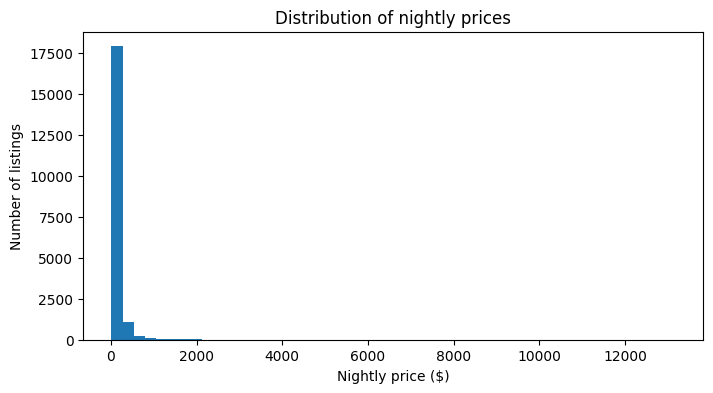

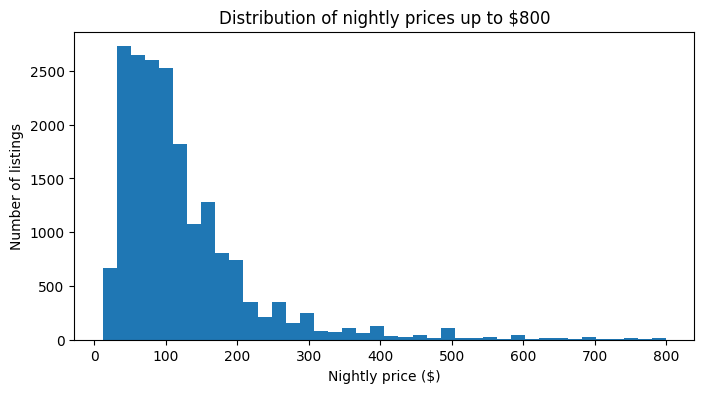

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(data["price"], bins=50)
plt.title("Distribution of nightly prices")
plt.xlabel("Nightly price ($)")
plt.ylabel("Number of listings")
plt.show()

data_plot = data[data["price"] <= 800]

plt.figure(figsize=(8, 4))
plt.hist(data_plot["price"], bins=40)
plt.title("Distribution of nightly prices up to $800")
plt.xlabel("Nightly price ($)")
plt.ylabel("Number of listings")
plt.show()

## 6. Protocole expérimental et choix des variables

## 7. Clustering avec K-means

## 8. Classification ascendante hiérarchique

## 9. Comparaison des méthodes de clustering

## 10. Régressions linéaires simple et multiple

## 11. Classification avec KNN

## 12. Synthèse des résultats, limites et conclusion

## 13. Sources et instructions de reproduction